In [3]:
import cv2
import numpy as np


image = cv2.imread('apple.png', cv2.IMREAD_GRAYSCALE)

# Применение детектора Кэнни
edges = cv2.Canny(image, 50, 150)

# Отображение
cv2.imshow('Canny Edges', edges)
cv2.waitKey(0)
cv2.destroyAllWindows()

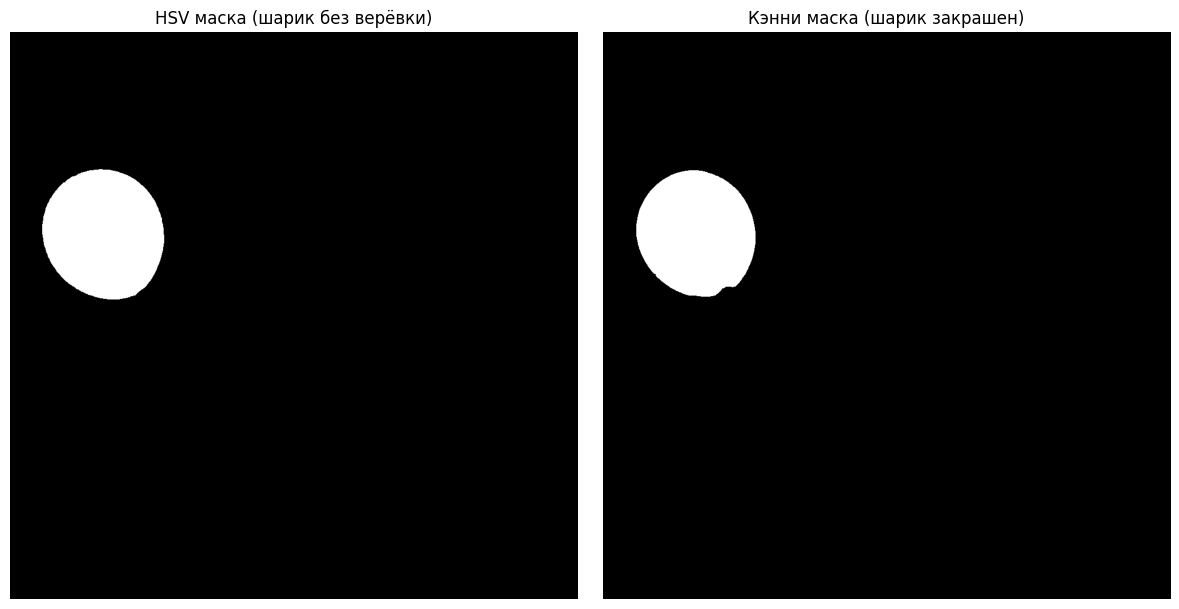

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


img = cv2.imread('5sharik.jpg')


hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)



# Диапазон жёлтого цвета 
lower_yellow = np.array([20, 90, 90])
upper_yellow = np.array([35, 255, 255])

# Бинарная маска по цвету
color_mask = cv2.inRange(hsv, lower_yellow, upper_yellow)

# Структурный элемент 
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (17, 17))


# заполняет блики и чёрные дырки внутри шарика
color_mask = cv2.morphologyEx(color_mask, cv2.MORPH_CLOSE, kernel)

# удаляет тонкие объекты (верёвку от шарика)
color_mask = cv2.morphologyEx(color_mask, cv2.MORPH_OPEN, kernel)




# Детектор границ Кэнни
edges = cv2.Canny(gray, 30, 100)

# Утолщаем границы, чтобы контур шарика стал замкнутым
edges = cv2.dilate(edges, None, iterations=3)

# Закрываем возможные разрывы в контуре
edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, kernel)

# =========================
# ЗАЛИВКА ОБЛАСТИ ШАРИКА
# =========================

# Подготавливаем маску для floodFill
h, w = edges.shape
ff_mask = np.zeros((h + 2, w + 2), np.uint8)

# Копия изображения с границами
filled = edges.copy()

# Заливаем фон (начинаем с угла, который точно фон)
cv2.floodFill(filled, ff_mask, (0, 0), 255)

# Инвертируем результат:
# теперь шарик — белый, фон — чёрный
canny_mask = cv2.bitwise_not(filled)

# Удаляем остатки верёвки и шум
canny_mask = cv2.morphologyEx(canny_mask, cv2.MORPH_OPEN, kernel)


fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# Цветовая маска
ax[0].imshow(color_mask, cmap='gray')
ax[0].set_title('HSV маска (шарик без верёвки)')
ax[0].axis('off')

# Маска Кэнни
ax[1].imshow(canny_mask, cmap='gray')
ax[1].set_title('Кэнни маска (шарик закрашен)')
ax[1].axis('off')

plt.tight_layout()
plt.show()


убрать дырку, заполнить маску кенни белым нужно закрыть контур 
убрать хвосты
